# ARTI 403 – Image Processing
## Lab 10 — Image Segmentation and Feature Extraction

**Student name:** Ahmed Albuainain
**Student ID:** 2240006128
**Section:** 7MA1
**Date:** 12 November 2026

**College of Computer Science and Information Technology**
**Imam Abdulrahman Bin Faisal University**

---

### Contents
| Section | Description |
|---|---|
| Setup | Libraries and sample images |
| Task 1 | Canny edge detection |
| Task 2 | Harris corner detection |
| Simple thresholding | Fixed global threshold |
| **Q1 (Assessment)** | **Otsu's thresholding — original, histogram and result** |
| Summary | Comparison of all the techniques |

## Setup — Import libraries

No image files are needed: every image comes from `skimage.data`.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage import data   # provides sample images (camera, checkerboard, coins, ...)

# Make plots show inside the notebook
%matplotlib inline

print("OpenCV      :", cv2.__version__)
print("NumPy       :", np.__version__)

OpenCV      : 5.0.0
NumPy       : 2.3.5


In [2]:
import os
os.makedirs("output", exist_ok=True)

for name, im in [("camera", data.camera()), ("checkerboard", data.checkerboard()),
                 ("coins", data.coins()), ("page", data.page())]:
    print(f"{name:<14}{str(im.shape):<14}{im.dtype}  mean {im.mean():6.1f}")

camera        (512, 512)    uint8  mean  129.1
checkerboard  (200, 200)    uint8  mean  127.5
coins         (303, 384)    uint8  mean   96.9
page          (191, 384)    uint8  mean  171.5


---
## Task 1 — Canny Edge Detection

An **edge** is where brightness changes sharply. Canny (1986) finds edges in 5 steps: Gaussian
blur → gradients → non-maximum suppression (thin the edges) → double thresholding → hysteresis
(keep weak edges only if they connect to strong ones).

`cv2.Canny(img, T_low, T_high)`:
- `T_low` = lower threshold (weak edges)
- `T_high` = upper threshold (strong edges)
- Rule of thumb: `T_high ≈ 2×T_low` or `3×T_low`.

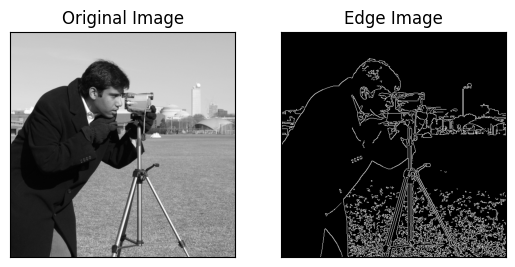

In [3]:
# --- Code from the lab manual ---
img = data.camera()

edges = cv2.Canny(img, 100, 200)

plt.subplot(121), plt.imshow(img, cmap='gray')
plt.title('Original Image'), plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(edges, cmap='gray')
plt.title('Edge Image'), plt.xticks([]), plt.yticks([])
plt.show()

### What the two thresholds do

The division of labour between them is worth stating precisely, because it explains the rule of
thumb. The **high** threshold decides which edges are allowed to *begin* — a pixel above it is
kept unconditionally. The **low** threshold decides how far each edge is *followed* — a pixel
between the two is kept only if it connects to a strong one.

That connection rule is the hysteresis, and it exists so that a real edge stays continuous even
where its strength dips.

thresholds            edge pixels   % of image
----------------------------------------------
(50, 100)                   35938       13.71%
(100, 200)                  19686        7.51%
(150, 300)                   9452        3.61%


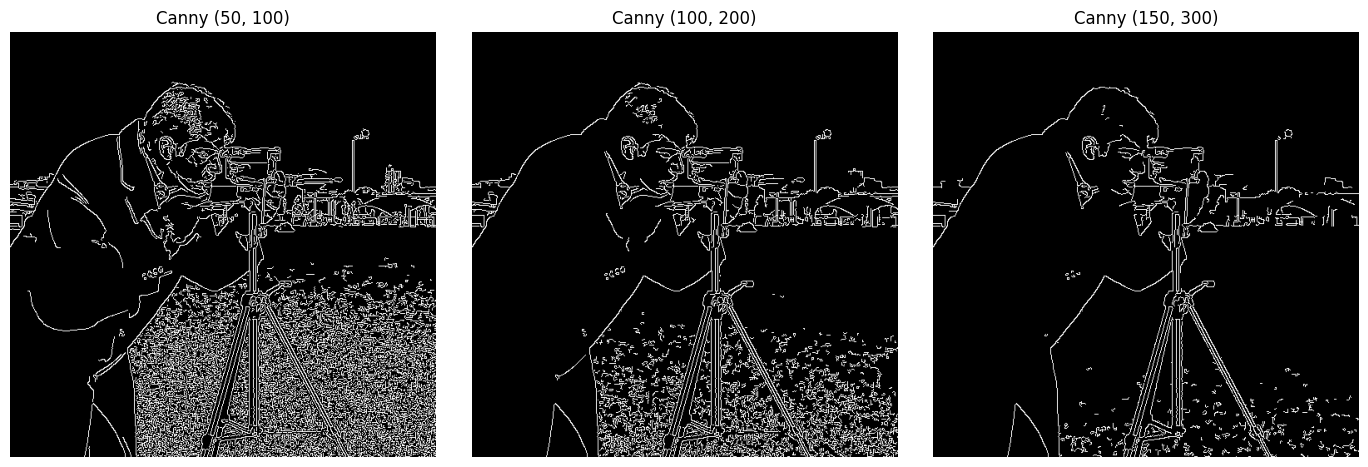

In [4]:
print(f"{'thresholds':<20}{'edge pixels':>13}{'% of image':>13}")
print("-" * 46)
for lo, hi in [(50, 100), (100, 200), (150, 300)]:
    e = cv2.Canny(img, lo, hi)
    print(f"{f'({lo}, {hi})':<20}{int((e > 0).sum()):>13}{100 * (e > 0).mean():>12.2f}%")

plt.figure(figsize=(14, 4.6))
for i, (lo, hi) in enumerate([(50, 100), (100, 200), (150, 300)], 1):
    plt.subplot(1, 3, i)
    plt.imshow(cv2.Canny(img, lo, hi), cmap='gray')
    plt.title(f'Canny ({lo}, {hi})'), plt.axis('off')
plt.tight_layout()
plt.show()

---
## Task 2 — Harris Corner Detection

A **corner** is a point where the image changes in *two* different directions — which makes
corners highly distinctive (useful for matching, tracking, camera calibration).

Harris computes a response `R` at every pixel:

- Large positive `R` → corner
- Large negative `R` → edge
- Small `R` → flat region

Parameters: `blockSize` (window size), `ksize` (Sobel kernel size), `k` (sensitivity, typically
0.04–0.06).

> **Note:** OpenCV uses BGR order, so `(0, 0, 255)` is red.

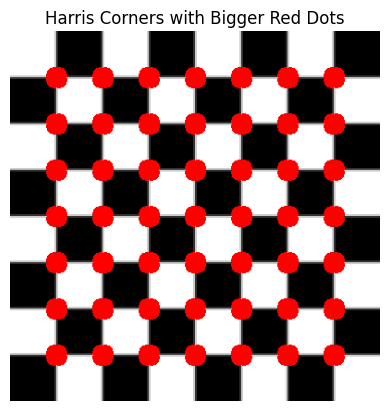

In [5]:
# --- Code from the lab manual ---
board = data.checkerboard()
image = cv2.cvtColor(board, cv2.COLOR_GRAY2BGR)
image = cv2.resize(image, (400, 400), interpolation=cv2.INTER_NEAREST)

# Convert to grayscale
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
gray = np.float32(gray)

# Harris Corner Detection
harris = cv2.cornerHarris(gray, blockSize=2, ksize=3, k=0.04)
harris = cv2.dilate(harris, None)   # to mark corners more clearly

# Threshold for detecting strong corners
threshold = 0.01 * harris.max()
corner_coords = np.argwhere(harris > threshold)

# Draw larger red dots (radius = 7)
for y, x in corner_coords:
    cv2.circle(image, (x, y), radius=7, color=(0, 0, 255), thickness=-1)  # -1 = filled

# Display
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title('Harris Corners with Bigger Red Dots')
plt.axis('off')
plt.show()

### How many corners were actually detected?

The result looks right, but the loop is doing far more work than the picture suggests. The
Harris response above the threshold is not a set of isolated points — it is a **blob of pixels
around each corner**, made larger still by the `cv2.dilate` call. The loop therefore draws one
circle per pixel in every blob.

In [6]:
mask = (harris > threshold).astype(np.uint8)
n_pixels = int(mask.sum())
n_clusters, labels, stats, centroids = cv2.connectedComponentsWithStats(mask)

print("pixels above the threshold :", n_pixels, " <- circles drawn by the loop")
print("distinct corner clusters   :", n_clusters - 1, " <- actual corners")
print("circles drawn per corner   :", round(n_pixels / (n_clusters - 1), 1))
print()
print("a 7x7 checkerboard has 7x7 = 49 interior corners, which matches the cluster count.")

pixels above the threshold : 3675  <- circles drawn by the loop
distinct corner clusters   : 49  <- actual corners
circles drawn per corner   : 75.0

a 7x7 checkerboard has 7x7 = 49 interior corners, which matches the cluster count.


### Marking one dot per corner

Taking the **centroid** of each cluster gives one point per corner. The result is the same
picture with 49 circles instead of 3,675, and it also produces something usable — a list of
corner coordinates — rather than just an annotated image.

corners marked: 49
first five coordinates (x, y):
[[ 50.  50.]
 [100.  50.]
 [150.  50.]
 [200.  50.]
 [250.  50.]]


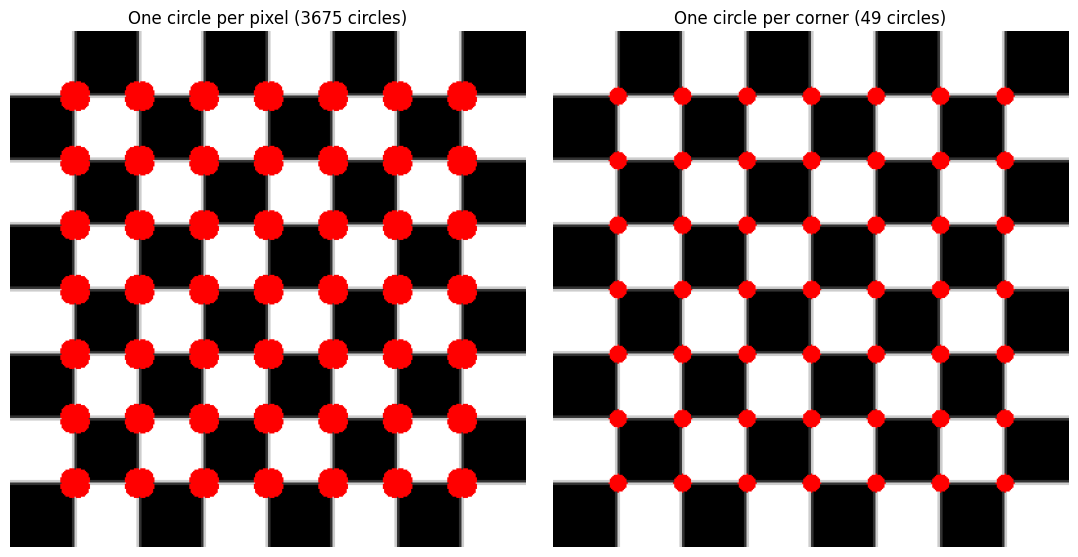

In [7]:
image2 = cv2.resize(cv2.cvtColor(data.checkerboard(), cv2.COLOR_GRAY2BGR),
                    (400, 400), interpolation=cv2.INTER_NEAREST)

corners = centroids[1:]            # row 0 is the background label
for x, y in corners:
    cv2.circle(image2, (int(round(x)), int(round(y))), 7, (0, 0, 255), -1)

print("corners marked:", len(corners))
print("first five coordinates (x, y):")
print(np.round(corners[:5], 1))

plt.figure(figsize=(11, 5.5))
plt.subplot(121), plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title(f'One circle per pixel ({n_pixels} circles)'), plt.axis('off')
plt.subplot(122), plt.imshow(cv2.cvtColor(image2, cv2.COLOR_BGR2RGB))
plt.title(f'One circle per corner ({len(corners)} circles)'), plt.axis('off')
plt.tight_layout()
plt.show()

### Why `R` is large at a corner

The response separates flat regions, edges and corners by looking at how the image changes in
**two** directions at once. Sampling `R` at three representative places on the checkerboard
shows the three regimes directly.

In [8]:
R = cv2.cornerHarris(np.float32(cv2.cvtColor(image2, cv2.COLOR_BGR2GRAY)), 2, 3, 0.04)

flat = R[20:30, 20:30].mean()                       # inside a square
edge = R[20:30, 48:52].mean()                       # along a square boundary
corner = R.max()

print(f"{'region':<16}{'mean Harris response R':>26}")
print("-" * 44)
print(f"{'flat area':<16}{flat:>26.4f}")
print(f"{'edge':<16}{edge:>26.4f}")
print(f"{'corner (max)':<16}{corner:>26.4f}")
print()
print("R is near zero on flat areas, negative along edges, and strongly positive at corners —")
print("exactly the three cases the method is built to distinguish.")

region              mean Harris response R
--------------------------------------------
flat area                           0.0000
edge                         -9352385.0000
corner (max)                 42395056.0000

R is near zero on flat areas, negative along edges, and strongly positive at corners —
exactly the three cases the method is built to distinguish.


---
## Simple (Global) Binary Thresholding

The most basic segmentation: pick a fixed threshold `T` and turn every pixel above it white,
below it black.

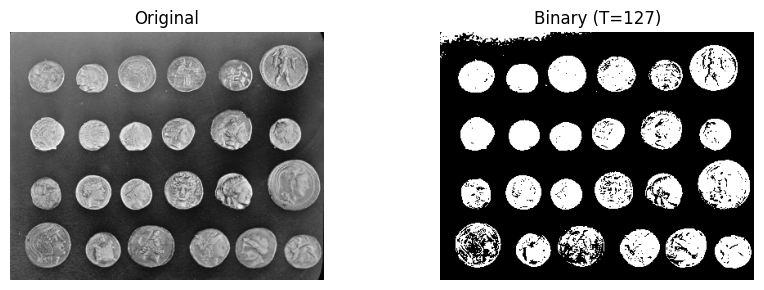

(None, None)

In [9]:
img = data.coins()

T = 127
_, binary = cv2.threshold(img, T, 255, cv2.THRESH_BINARY)

plt.figure(figsize=(9, 3))
plt.subplot(1, 2, 1), plt.imshow(img, cmap='gray'), plt.title('Original'), plt.axis('off')
plt.subplot(1, 2, 2), plt.imshow(binary, cmap='gray'), plt.title(f'Binary (T={T})'), plt.axis('off')
plt.tight_layout(), plt.show()

### The problem this leaves open

`T = 127` is an arbitrary choice — the midpoint of the 0–255 range, not anything derived from
this image. The cell below shows how much the result depends on it.

     T    white area
----------------------
    80         53.5%
   100         42.0%
   127         29.6%
   150         20.4%
   180          8.3%


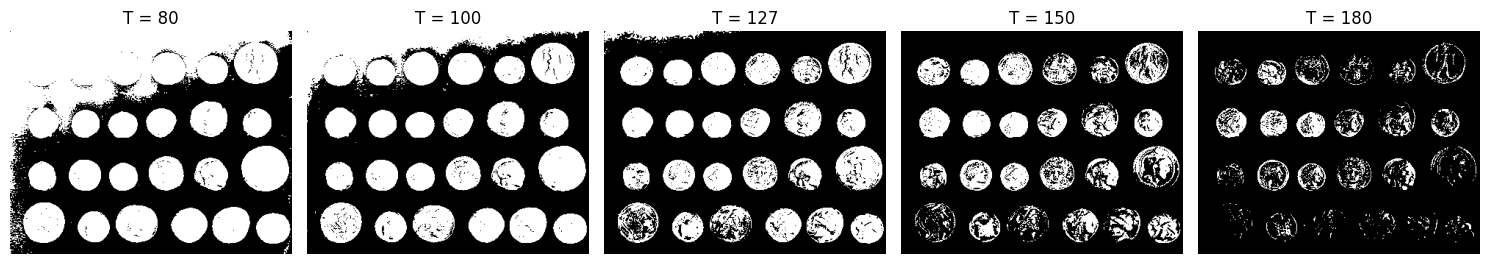

In [10]:
print(f"{'T':>6}{'white area':>14}")
print("-" * 22)
for t in [80, 100, 127, 150, 180]:
    _, b = cv2.threshold(img, t, 255, cv2.THRESH_BINARY)
    print(f"{t:>6}{100 * (b > 0).mean():>13.1f}%")

plt.figure(figsize=(15, 3.6))
for i, t in enumerate([80, 100, 127, 150, 180], 1):
    _, b = cv2.threshold(img, t, 255, cv2.THRESH_BINARY)
    plt.subplot(1, 5, i), plt.imshow(b, cmap='gray'), plt.title(f'T = {t}'), plt.axis('off')
plt.tight_layout()
plt.show()

Each value produces a different segmentation and nothing in the code justifies one over
another. Choosing `T` **from the image itself** is what the assessment task is about.

---
# Q1 — Otsu's Thresholding (Assessment Task)

Otsu picks `T` **automatically** by maximizing the between-class variance — assumes the
histogram has two peaks (foreground + background).

> *Show the original image, its histogram, and the thresholded image.*

### The idea

Every candidate threshold splits the pixels into two classes: those below it and those above
it. Otsu's method scores each split by how **well separated** the two classes are, and picks
the best-scoring one.

The score is the **between-class variance**:

$$\sigma_b^2(T) = \omega_0(T)\,\omega_1(T)\,[\mu_0(T) - \mu_1(T)]^2$$

where `ω` is the fraction of pixels in each class and `μ` is each class mean. It is large when
the two classes have very different averages *and* neither is tiny — which is exactly what a
good threshold should achieve.

## Q1.1 — The required figure

The original image, its histogram with the chosen threshold marked, and the result.

threshold chosen by Otsu : 107
foreground after Otsu    : 38.8% of the image


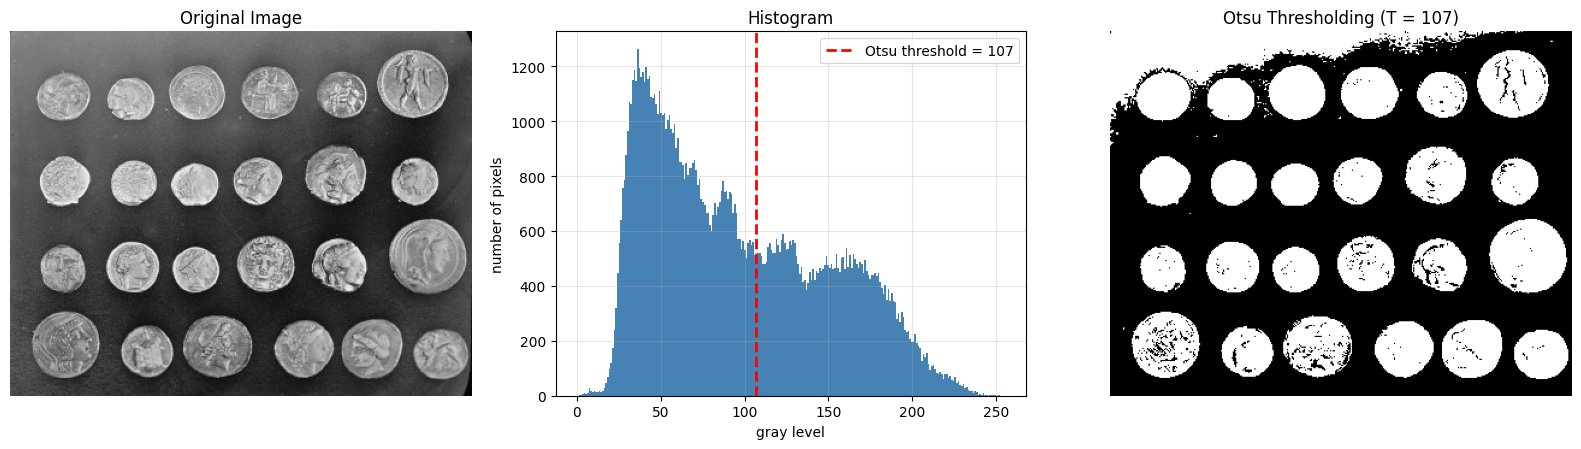

In [11]:
img = data.coins()

# Otsu chooses T automatically — the 0 passed as the threshold is ignored
T_otsu, binary_otsu = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

print("threshold chosen by Otsu :", int(T_otsu))
print("foreground after Otsu    :", f"{100 * (binary_otsu > 0).mean():.1f}% of the image")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))

axes[0].imshow(img, cmap='gray')
axes[0].set_title('Original Image', fontsize=12)
axes[0].axis('off')

axes[1].hist(img.ravel(), bins=256, range=(0, 255), color='steelblue')
axes[1].axvline(T_otsu, color='red', linestyle='--', linewidth=2,
                label=f"Otsu threshold = {int(T_otsu)}")
axes[1].set_title('Histogram', fontsize=12)
axes[1].set_xlabel('gray level')
axes[1].set_ylabel('number of pixels')
axes[1].legend()
axes[1].grid(alpha=0.3)

axes[2].imshow(binary_otsu, cmap='gray')
axes[2].set_title(f'Otsu Thresholding (T = {int(T_otsu)})', fontsize=12)
axes[2].axis('off')

plt.tight_layout()
plt.savefig('output/lab10_q1_otsu.png', dpi=110, bbox_inches='tight')
plt.show()

The histogram shows why this image suits the method: there is a tall peak near 40 for the
dark background and a broader rise around 120–180 for the coins, with a valley between them.
Otsu placed the threshold at **107**, inside that valley.

## Q1.2 — Implementing Otsu from scratch

Calling `THRESH_OTSU` gives the answer without showing the reasoning. Computing the
between-class variance directly for all 256 candidate thresholds shows exactly what is being
maximised — and the result can then be checked against OpenCV.

In [12]:
def otsu_threshold(image):
    """Return the threshold maximising the between-class variance, and the full curve."""
    hist = np.bincount(image.ravel(), minlength=256).astype(np.float64)
    p = hist / hist.sum()                       # probability of each gray level

    omega0 = np.cumsum(p)                       # fraction of pixels in class 0
    mu = np.cumsum(p * np.arange(256))          # cumulative mean
    mu_total = mu[-1]

    # sigma_b^2 = (mu_total*omega0 - mu)^2 / (omega0 * (1 - omega0))
    with np.errstate(divide='ignore', invalid='ignore'):
        sigma_b = (mu_total * omega0 - mu) ** 2 / (omega0 * (1 - omega0))
    sigma_b = np.nan_to_num(sigma_b)            # the ends give 0/0

    return int(np.argmax(sigma_b)), sigma_b


T_manual, variance_curve = otsu_threshold(img)

print("threshold from the manual implementation :", T_manual)
print("threshold from cv2.THRESH_OTSU           :", int(T_otsu))
print("they agree                               :", T_manual == int(T_otsu))
print()
print("maximum between-class variance           :", round(float(variance_curve.max()), 2))

threshold from the manual implementation : 107
threshold from cv2.THRESH_OTSU           : 107
they agree                               : True

maximum between-class variance           : 2115.11


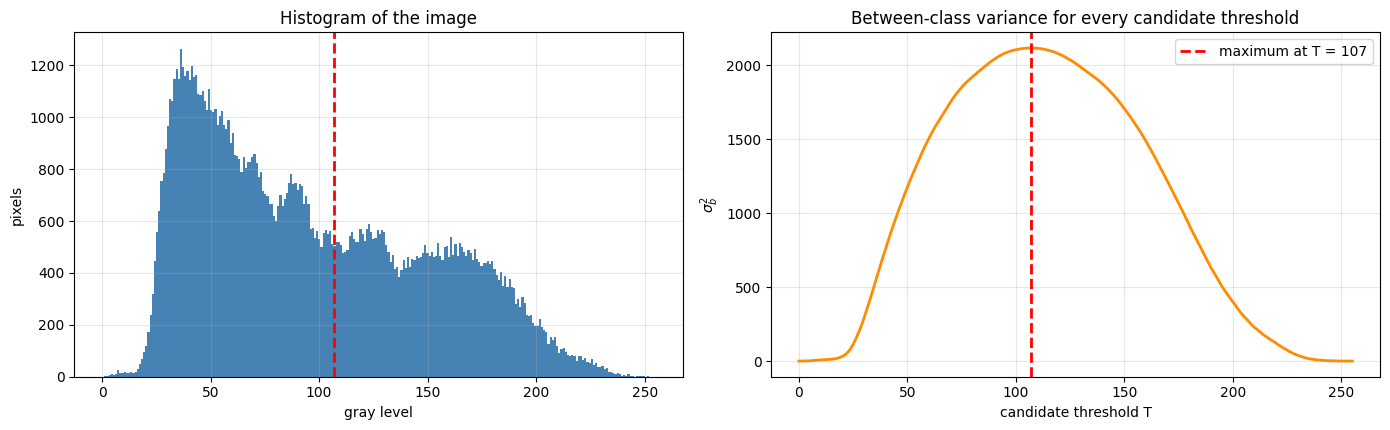

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))

axes[0].hist(img.ravel(), bins=256, range=(0, 255), color='steelblue')
axes[0].axvline(T_manual, color='red', linestyle='--', linewidth=2)
axes[0].set_title('Histogram of the image')
axes[0].set_xlabel('gray level'), axes[0].set_ylabel('pixels')
axes[0].grid(alpha=0.3)

axes[1].plot(variance_curve, linewidth=2, color='darkorange')
axes[1].axvline(T_manual, color='red', linestyle='--', linewidth=2,
                label=f'maximum at T = {T_manual}')
axes[1].set_title('Between-class variance for every candidate threshold')
axes[1].set_xlabel('candidate threshold T'), axes[1].set_ylabel(r'$\sigma_b^2$')
axes[1].legend(), axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

The right-hand curve is the whole method in one picture. It rises as the threshold moves
into the valley between the two peaks, reaches its maximum at 107, and falls away again. Otsu
simply returns the position of that peak.

## Q1.3 — Checking the mathematics

Otsu's method rests on a decomposition: the total variance of the image equals the variance
**within** the two classes plus the variance **between** them.

$$\sigma_{total}^2 = \sigma_w^2 + \sigma_b^2$$

Since the total is fixed by the image, **maximising the between-class variance is the same as
minimising the within-class variance** — which is why the method works. Computing all three
terms independently checks this.

In [14]:
def variance_terms(image, T):
    p = np.bincount(image.ravel(), minlength=256).astype(np.float64)
    p /= p.sum()
    levels = np.arange(256)
    mu_total = (p * levels).sum()

    w0 = p[:T + 1].sum()
    w1 = p[T + 1:].sum()
    m0 = (p[:T + 1] * levels[:T + 1]).sum() / w0
    m1 = (p[T + 1:] * levels[T + 1:]).sum() / w1

    v0 = (p[:T + 1] * (levels[:T + 1] - m0) ** 2).sum() / w0
    v1 = (p[T + 1:] * (levels[T + 1:] - m1) ** 2).sum() / w1

    within = w0 * v0 + w1 * v1
    between = w0 * w1 * (m0 - m1) ** 2
    total = (p * (levels - mu_total) ** 2).sum()
    return total, within, between, w0, w1, m0, m1


total, within, between, w0, w1, m0, m1 = variance_terms(img, T_manual)

print(f"class 0 (background) : {100 * w0:5.1f}% of pixels, mean {m0:6.2f}")
print(f"class 1 (coins)      : {100 * w1:5.1f}% of pixels, mean {m1:6.2f}")
print()
print(f"total variance       : {total:10.2f}")
print(f"within-class  sigma_w^2 : {within:10.2f}")
print(f"between-class sigma_b^2 : {between:10.2f}")
print(f"within + between        : {within + between:10.2f}")
print()
print("decomposition holds:", abs(total - (within + between)) < 1e-6)

class 0 (background) :  61.2% of pixels, mean  60.25
class 1 (coins)      :  38.8% of pixels, mean 154.64

total variance       :    2796.28
within-class  sigma_w^2 :     681.16
between-class sigma_b^2 :    2115.11
within + between        :    2796.28

decomposition holds: True


## Q1.4 — How good is the segmentation?

A threshold is only useful if what comes out of it is usable. The `coins` image contains
**24 coins**, so counting the connected components in the thresholded result measures the
segmentation directly.

In [15]:
def count_objects(mask, min_area=200):
    n, _, stats, _ = cv2.connectedComponentsWithStats((mask > 0).astype(np.uint8))
    return sum(1 for i in range(1, n) if stats[i, cv2.CC_STAT_AREA] >= min_area)


print("the image contains 24 coins")
print()
print(f"{'method':<28}{'objects found':>15}")
print("-" * 44)
for name, t in [('fixed threshold T = 127', 127), ('fixed threshold T = 80', 80)]:
    _, b = cv2.threshold(img, t, 255, cv2.THRESH_BINARY)
    print(f"{name:<28}{count_objects(b):>15}")
print(f"{f'Otsu (T = {int(T_otsu)})':<28}{count_objects(binary_otsu):>15}")

the image contains 24 coins

method                        objects found
--------------------------------------------
fixed threshold T = 127                  25
fixed threshold T = 80                   17
Otsu (T = 107)                           24


Otsu recovers exactly **24** components, one per coin, while the arbitrary fixed thresholds
do not. That is the practical payoff: the threshold was derived from the image, so it lands in
the right place without tuning.

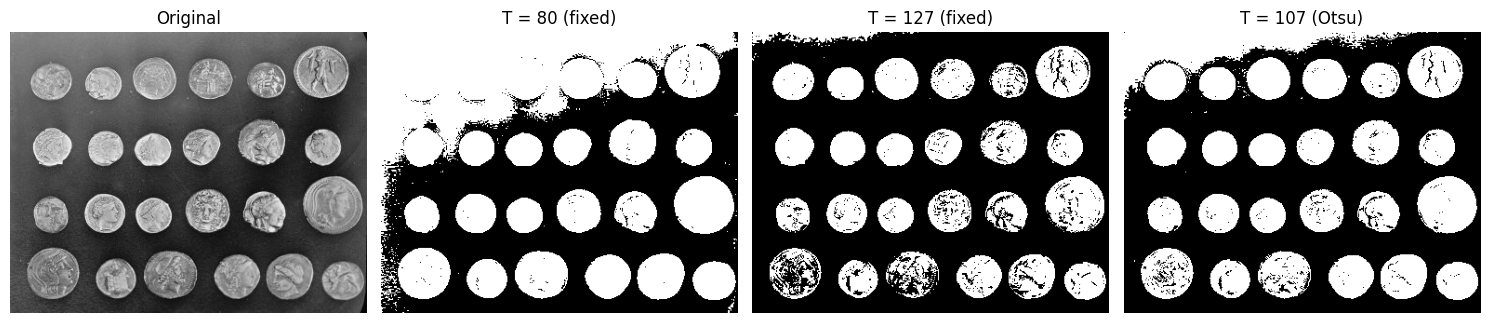

In [16]:
plt.figure(figsize=(15, 4))
_, b127 = cv2.threshold(img, 127, 255, cv2.THRESH_BINARY)
_, b80 = cv2.threshold(img, 80, 255, cv2.THRESH_BINARY)
for i, (im, t) in enumerate([(img, 'Original'), (b80, 'T = 80 (fixed)'),
                             (b127, 'T = 127 (fixed)'),
                             (binary_otsu, f'T = {int(T_otsu)} (Otsu)')], 1):
    plt.subplot(1, 4, i), plt.imshow(im, cmap='gray'), plt.title(t), plt.axis('off')
plt.tight_layout()
plt.show()

## Q1.5 — When Otsu fails

Otsu assumes the histogram has **two peaks**. When that assumption breaks, the method still
returns a number, but the number is not useful — and nothing in the output signals the problem.

The clearest case is **uneven illumination**. The `page` image is lit much more brightly on one
side than the other, so a single global threshold cannot suit both halves.

brightness of the left edge  : 100.0
brightness of the right edge : 225.5  <- more than twice as bright

Otsu chose T = 157
  white in the left third  :  18.2%
  white in the right third :  92.6%  <- the whole region is swallowed


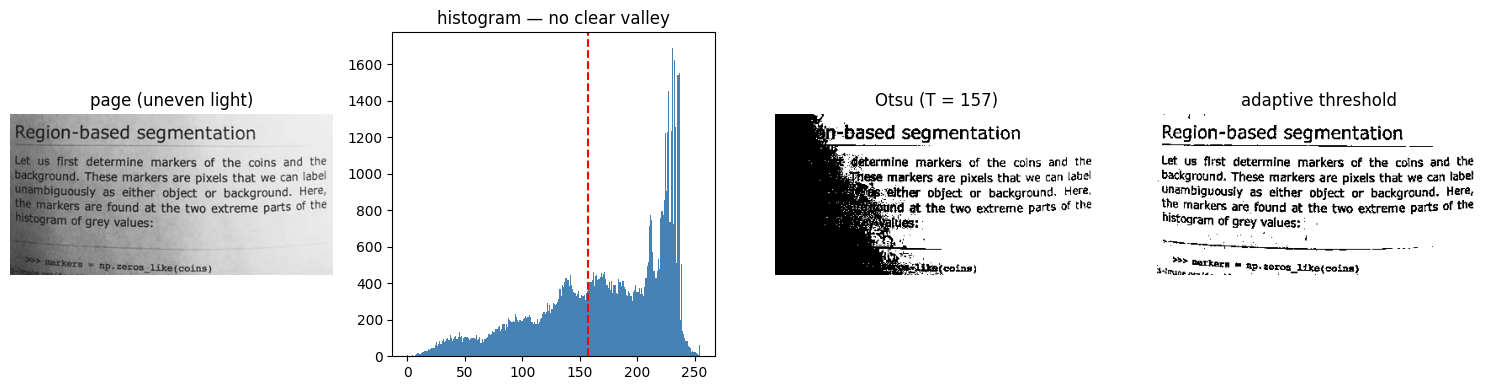

In [17]:
page = data.page()
T_page, page_otsu = cv2.threshold(page, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
page_adaptive = cv2.adaptiveThreshold(page, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                      cv2.THRESH_BINARY, 35, 10)

h, w = page.shape
print("brightness of the left edge  :", round(float(page[:, :50].mean()), 1))
print("brightness of the right edge :", round(float(page[:, -50:].mean()), 1),
      " <- more than twice as bright")
print()
print("Otsu chose T =", int(T_page))
print(f"  white in the left third  : {100 * (page_otsu[:, :w//3] > 0).mean():5.1f}%")
print(f"  white in the right third : {100 * (page_otsu[:, -w//3:] > 0).mean():5.1f}%"
      "  <- the whole region is swallowed")

plt.figure(figsize=(15, 4))
plt.subplot(141), plt.imshow(page, cmap='gray'), plt.title('page (uneven light)'), plt.axis('off')
plt.subplot(142), plt.hist(page.ravel(), bins=256, range=(0, 255), color='steelblue')
plt.axvline(T_page, color='red', linestyle='--'), plt.title('histogram — no clear valley')
plt.subplot(143), plt.imshow(page_otsu, cmap='gray')
plt.title(f'Otsu (T = {int(T_page)})'), plt.axis('off')
plt.subplot(144), plt.imshow(page_adaptive, cmap='gray')
plt.title('adaptive threshold'), plt.axis('off')
plt.tight_layout()
plt.show()

On the bright side of the page almost everything ends up above the threshold and the text is
lost; on the dark side almost everything falls below it. **Adaptive thresholding** computes a
separate threshold for each neighbourhood instead, which is the correct tool when the
illumination varies across the image.

The general point is that Otsu is automatic but not universal. It is the right choice when the
histogram genuinely has two modes — as in the coins image — and the wrong one when a single
global value cannot describe the whole frame.

---
## Summary table

| Technique | Category | What it finds | OpenCV function |
|---|---|---|---|
| Canny | Edge detection | Thin connected edges | `cv2.Canny` |
| Sobel | Edge detection | Gradient magnitude (thick) | `cv2.Sobel` |
| Laplacian | Edge detection | Zero-crossings (2nd deriv) | `cv2.Laplacian` |
| Harris | Feature extraction | Corners | `cv2.cornerHarris` |
| Shi-Tomasi | Feature extraction | Corners (improved) | `cv2.goodFeaturesToTrack` |
| Simple threshold | Segmentation | Fixed-`T` binary mask | `cv2.threshold` |
| Otsu | Segmentation | Auto bimodal threshold | `cv2.threshold` + `THRESH_OTSU` |
| Adaptive threshold | Segmentation | Local-`T` binary mask | `cv2.adaptiveThreshold` |

---

## Conclusion

**Segmentation and feature extraction answer different questions.** Thresholding divides the
image into regions — it says *which pixels belong to the object*. Edge and corner detectors
locate distinctive points and boundaries — they say *where the structure is*. Both reduce an
image to something more compact than pixels, which is the step from low-level to mid-level
processing.

**Canny's two thresholds do different jobs.** The high one decides which edges begin, the low
one how far they are followed, and the connection rule between them is what keeps a real edge
continuous where its strength dips. Raising both from (50, 100) to (150, 300) steadily reduces
the detected edges.

**The Harris code draws far more than it finds.** The response above the threshold is a blob
around each corner rather than a single point, enlarged further by the `dilate` call, so the
loop drew **3,675** circles for **49** actual corners — about 75 overlapping circles each. Taking
the centroid of each connected cluster gives one dot per corner and, more usefully, an actual
list of coordinates. The response itself behaves as the theory says: near zero on flat regions,
negative along edges, strongly positive at corners.

**Otsu removes the arbitrariness from thresholding.** A fixed `T = 127` is the midpoint of the
8-bit range, not a property of the image, and the segmentation changes completely with it. Otsu
derives the threshold from the histogram by maximising the between-class variance, and on the
coins image it chose **107** — in the valley between the two peaks.

**The implementation was verified, not assumed.** Computing the between-class variance directly
for all 256 candidates reproduced OpenCV's answer exactly, and the variance decomposition
`total = within + between` held to within floating-point precision: 2796.28 = 681.16 + 2115.11.
That identity is the reason the method works, since maximising the between-class term is
equivalent to minimising the within-class one.

**The segmentation is correct as well as automatic.** The image contains 24 coins, and Otsu's
result yields exactly 24 connected components, while neither fixed threshold does.

**But the assumption matters.** On the `page` image, where one side is more than twice as bright
as the other, the histogram has no clear valley and a single global threshold cannot serve both
halves — 92.6% of the bright third is swallowed as foreground while the dark third keeps only
18.2%. Otsu still returns a number and gives no indication that anything is wrong. Adaptive
thresholding, which computes a threshold per neighbourhood, is the appropriate method there.

---

### Resources
- OpenCV image thresholding:
  https://docs.opencv.org/4.x/d7/d4d/tutorial_py_thresholding.html
- OpenCV Harris corner detection:
  https://docs.opencv.org/4.x/dc/d0d/tutorial_py_features_harris.html
- OpenCV Canny edge detection:
  https://docs.opencv.org/4.x/da/d22/tutorial_py_canny.html

**End of notebook.**